# PlantMetWiki and the spectral libraries: connectivity

How are PlantMetWiki compounds connected to the CASMI 2026 training libraries? Every link is a shared `inchikey14` (first block of the InChIKey, so stereoisomers and charge forms of one skeleton match). Input: the tables of [../casmi_overlap.py](../casmi_overlap.py); this notebook does not read the 2.8 GB parquet.

Numbers are counts of PlantMetWiki compounds (2,732 with an InChIKey), not spectra. One figure per question:

1. How many PlantMetWiki compounds does each library cover?
2. How do the libraries overlap, and which add something new?
3. Which kinds of pathways are covered (primary vs specialized)?
4. Which pathway classes are covered by which library?

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, networkx as nx

HERE = Path.cwd().parent
RES = HERE / "results"; MD = HERE.parent / "metabolomics_overlap" / "data"
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11})
BLUE, GREY = "#1f6fb4", "#9aa3ad"

comp = pd.read_csv(RES / "overlap_compounds.csv")
per = pd.read_csv(RES / "overlap_per_library.csv"); per = per[per.library != "ALL"]
pmw = pd.read_csv(MD / "plantmetwiki_metabolites.csv"); pmw["k14"] = pmw.inchikey.str[:14]
N = pmw.k14.nunique()
S = {lib: set(comp.inchikey14[comp.libraries.str.split(";").apply(lambda l: lib in l)]) for lib in per.library}
LIBS = sorted(S, key=lambda l: -len(S[l]))
print(N, "PlantMetWiki compounds;", len(comp), "with a spectrum in at least one library")

2732 PlantMetWiki compounds; 1258 with a spectrum in at least one library


## 1. Coverage per library

How many of the 2,732 compounds does each library hold? The grey part is the rest of PlantMetWiki.

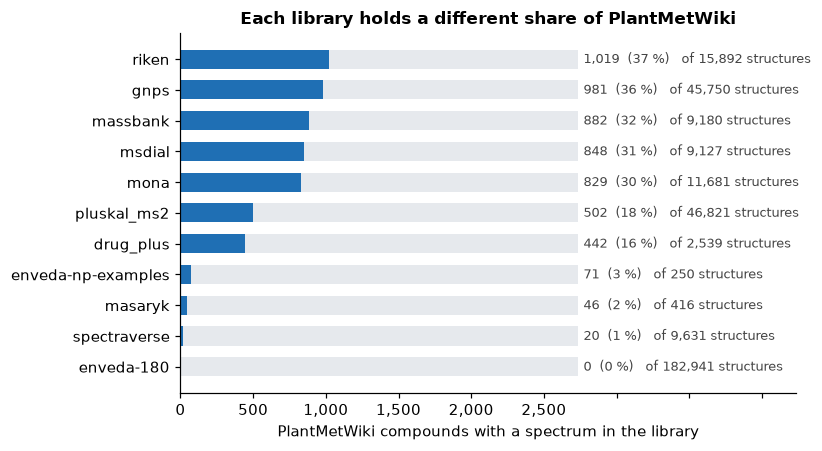

In [2]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
y = np.arange(len(LIBS))[::-1]
n = np.array([len(S[l]) for l in LIBS])
ax.barh(y, [N] * len(LIBS), color="#e6e9ed", height=0.62)
ax.barh(y, n, color=BLUE, height=0.62)
for yi, l, v in zip(y, LIBS, n):
    st = int(per.set_index("library").structures[l])
    ax.text(N + 40, yi, f"{v:,}  ({100 * v / N:.0f} %)   of {st:,} structures", va="center", fontsize=8.5, color="#444")
ax.set_yticks(y); ax.set_yticklabels(LIBS); ax.set_xlim(0, N * 1.55)
ax.set_xlabel("PlantMetWiki compounds with a spectrum in the library"); ax.set_title("Each library holds a different share of PlantMetWiki")
ax.xaxis.set_major_formatter(lambda v, p: f"{int(v):,}" if v <= N else "")
fig.tight_layout(); fig.savefig(FIG / "lib_coverage.png"); plt.show()

`enveda-180` holds 183k structures and none of them is in PlantMetWiki: it is a synthetic drug-like set. The libraries that hold natural products and metabolites (RIKEN, GNPS, MassBank, MS-DIAL, MoNA) each cover about a third of PlantMetWiki (30 to 37 %).

## 2. Overlap between libraries

Left: of the compounds a library holds (row), the share that is also in another library (column). Right: the library network, edge width = shared compounds.

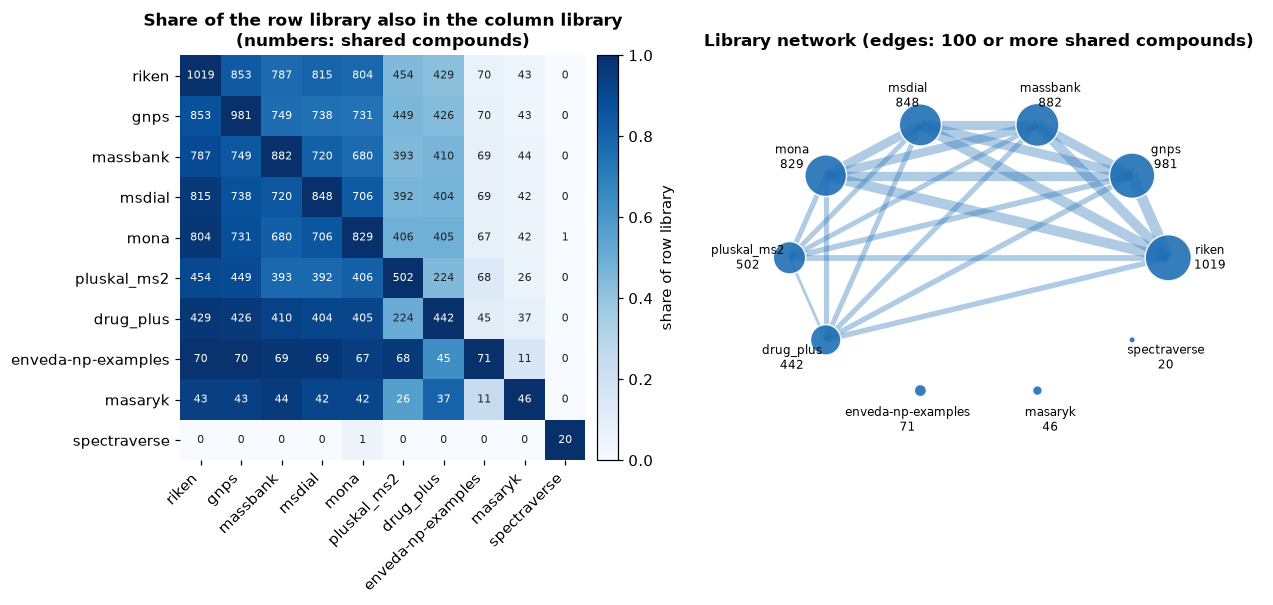

In [3]:
use = [l for l in LIBS if len(S[l]) > 0]
M = np.array([[len(S[a] & S[b]) / len(S[a]) for b in use] for a in use])
C = np.array([[len(S[a] & S[b]) for b in use] for a in use])
fig, axs = plt.subplots(1, 2, figsize=(13, 5.6), gridspec_kw={"width_ratios": [1.05, 1]})
ax = axs[0]
im = ax.imshow(M, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(use))); ax.set_xticklabels(use, rotation=45, ha="right"); ax.set_yticks(range(len(use))); ax.set_yticklabels(use)
for i in range(len(use)):
    for j in range(len(use)):
        ax.text(j, i, f"{C[i, j]}", ha="center", va="center", fontsize=7.5, color="white" if M[i, j] > 0.55 else "#222")
ax.set_title("Share of the row library also in the column library\n(numbers: shared compounds)")
for s in ax.spines.values(): s.set_visible(False)
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label="share of row library")
ax = axs[1]
G = nx.Graph()
for l in use: G.add_node(l, size=len(S[l]))
for a in range(len(use)):
    for b in range(a + 1, len(use)):
        w = len(S[use[a]] & S[use[b]])
        if w >= 100: G.add_edge(use[a], use[b], w=w)
pos = nx.circular_layout(G)
nx.draw_networkx_edges(G, pos, ax=ax, width=[G[u][v]["w"] / 120 for u, v in G.edges], alpha=0.35, edge_color=BLUE)
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=[G.nodes[l]["size"] * 0.9 for l in G], node_color=BLUE, alpha=0.9, edgecolors="white")
for l, (x, yv) in pos.items():
    ax.text(x * 1.22, yv * 1.22, f"{l}\n{len(S[l])}", ha="center", va="center", fontsize=8)
ax.set_xlim(-1.5, 1.5); ax.set_ylim(-1.45, 1.45); ax.axis("off")
ax.set_title("Library network (edges: 100 or more shared compounds)")
fig.tight_layout(); fig.savefig(FIG / "lib_overlap.png"); plt.show()

The five large natural-product and metabolite libraries overlap strongly (each shares about 700 to 850 compounds with the others), and the smaller ones (`drug_plus`, `enveda-np-examples`, `masaryk`) are mostly contained in them. **`spectraverse` is the exception:** its 20 compounds are almost all absent from every other library (19 are unique). That is unexpected for an aggregation of public libraries; I have not checked why (different key format or a different part of chemical space). Next: what does each library add that no other has?

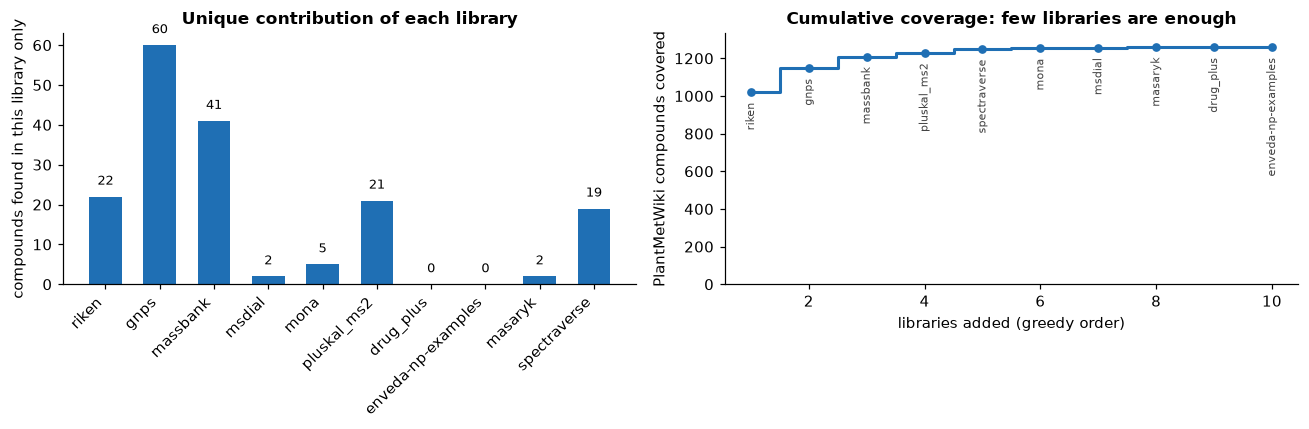

{'riken': 1019, 'gnps': 1147, 'massbank': 1207, 'pluskal_ms2': 1229, 'spectraverse': 1249, 'mona': 1254, 'msdial': 1256, 'masaryk': 1258, 'drug_plus': 1258, 'enveda-np-examples': 1258}


In [4]:
allc = set(comp.inchikey14)
only = {l: len({k for k in S[l] if all(k not in S[o] for o in use if o != l)}) for l in use}
rem, order, cum = set(allc), [], []
left = set(use)
while left:                                   # greedy: each step adds the library covering most uncovered compounds
    best = max(left, key=lambda l: len(S[l] & rem)); order.append(best); rem -= S[best]; cum.append(len(allc) - len(rem)); left.remove(best)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
ax = axs[0]
ax.bar(range(len(use)), [only[l] for l in use], color=BLUE, width=0.6)
for i, l in enumerate(use): ax.text(i, only[l] + 3, only[l], ha="center", fontsize=8.5)
ax.set_xticks(range(len(use))); ax.set_xticklabels(use, rotation=45, ha="right"); ax.set_ylabel("compounds found in this library only")
ax.set_title("Unique contribution of each library")
ax = axs[1]
ax.step(range(1, len(order) + 1), cum, where="mid", color=BLUE, lw=2); ax.scatter(range(1, len(order) + 1), cum, color=BLUE, s=22, zorder=3)
for i, (l, c) in enumerate(zip(order, cum)): ax.text(i + 1, c - 55, l, rotation=90, ha="center", va="top", fontsize=7.5, color="#444")
ax.set_ylim(0, len(allc) * 1.06); ax.set_xlabel("libraries added (greedy order)"); ax.set_ylabel("PlantMetWiki compounds covered")
ax.set_title("Cumulative coverage: few libraries are enough")
fig.tight_layout(); fig.savefig(FIG / "lib_unique_cumulative.png"); plt.show()
print(dict(zip(order, cum)))

## 3. Which pathways are covered: primary or specialized?

Pathway classes come from PlantCyc (`pathway_class_categories.csv`). A pathway is called *specialized* if any of its classes is specialized (secondary), else *hormones*, else *primary*; the rest is *other*. A compound counts in every category in which it has a pathway.

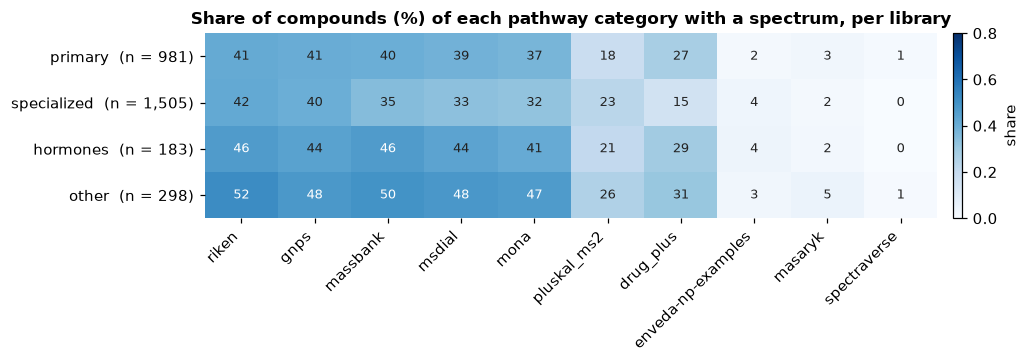

{'primary': 49.3, 'specialized': 51.2, 'hormones': 53.0, 'other': 59.1} % of each category with a spectrum in any library


In [5]:
cls = pd.read_csv(MD / "plantmetwiki_pathway_classes.csv"); cat = pd.read_csv(MD / "pathway_class_categories.csv")
cls = cls.merge(cat, on="class", how="left")
def pcat(g):
    c = set(g.category.dropna())
    for k, lab in (("specialized (secondary)", "specialized"), ("hormones", "hormones"), ("primary", "primary")):
        if k in c: return lab
    return "other"
pcategory = cls.groupby("plantcyc_id").apply(pcat, include_groups=False).rename("pcat").reset_index()
mp = pd.read_csv(MD / "plantmetwiki_metabolite_pathways.csv", dtype=str)
mp = mp[~mp.plantcyc_id.str.contains("RXN")]; mp["k14"] = mp.inchikey.str[:14]
mp = mp.merge(pcategory, on="plantcyc_id", how="left").fillna({"pcat": "other"})
CATS = ["primary", "specialized", "hormones", "other"]
tot = {c: set(mp.k14[mp.pcat == c]) for c in CATS}
rows = [[len(tot[c] & S[l]) / len(tot[c]) for l in use] for c in CATS]
fig, ax = plt.subplots(figsize=(9.5, 3.4))
im = ax.imshow(rows, cmap="Blues", vmin=0, vmax=0.8, aspect="auto")
ax.set_xticks(range(len(use))); ax.set_xticklabels(use, rotation=45, ha="right")
ax.set_yticks(range(len(CATS))); ax.set_yticklabels([f"{c}  (n = {len(tot[c]):,})" for c in CATS])
for i, c in enumerate(CATS):
    for j, l in enumerate(use):
        ax.text(j, i, f"{100 * rows[i][j]:.0f}", ha="center", va="center", fontsize=8.5, color="white" if rows[i][j] > 0.45 else "#222")
ax.set_title("Share of compounds (%) of each pathway category with a spectrum, per library")
for s in ax.spines.values(): s.set_visible(False)
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, label="share")
fig.tight_layout(); fig.savefig(FIG / "category_by_library.png"); plt.show()
print({c: round(100 * len(tot[c] & allc) / len(tot[c]), 1) for c in CATS}, "% of each category with a spectrum in any library")

Reading: at the level of compounds, coverage is about the same in every category: 49 % of the compounds of primary pathways, 51 % of specialized, 53 % of hormone and 59 % of other pathways have a spectrum in at least one library. Specialized pathways are not poorer in reference spectra per compound. Below, the same question at the level of pathways, where specialized pathways are slightly behind (median 56 % of the compounds covered against 62 % for primary).

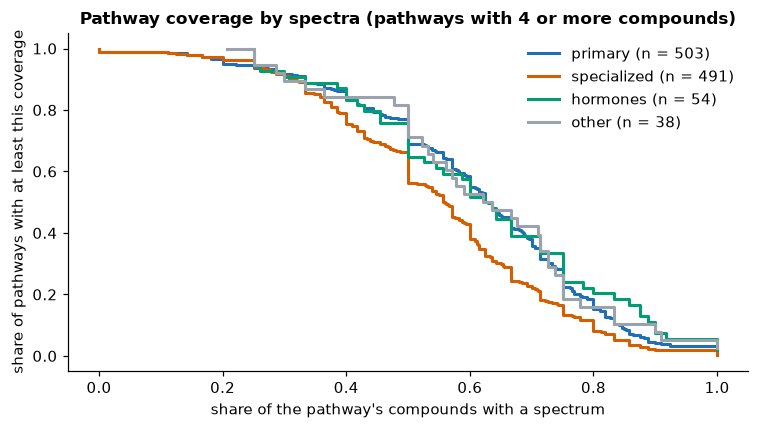

             count   25%   50%   75%
pcat                                
hormones      54.0  0.47  0.61  0.75
other         38.0  0.50  0.61  0.73
primary      503.0  0.50  0.62  0.75
specialized  491.0  0.41  0.56  0.67


In [6]:
cov = pd.read_csv(RES / "pathway_spectra_coverage.csv").merge(pcategory, on="plantcyc_id", how="left").fillna({"pcat": "other"})
big = cov[cov.members >= 4]
fig, ax = plt.subplots(figsize=(7, 4))
cols = {"primary": "#1f6fb4", "specialized": "#d55e00", "hormones": "#009e73", "other": GREY}
for c in CATS:
    d = np.sort(big.fraction[big.pcat == c].to_numpy())
    if len(d): ax.step(d, 1 - np.arange(len(d)) / len(d), where="post", color=cols[c], lw=2, label=f"{c} (n = {len(d)})")
ax.set_xlabel("share of the pathway's compounds with a spectrum"); ax.set_ylabel("share of pathways with at least this coverage")
ax.set_title("Pathway coverage by spectra (pathways with 4 or more compounds)"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "pathway_coverage_by_category.png"); plt.show()
print(big.groupby("pcat").fraction.describe()[["count", "25%", "50%", "75%"]].round(2))

## 4. Pathway classes and libraries

The 22 largest classes of non-reaction pathways (by compounds). Cell: share of the class's compounds with a spectrum in the library.

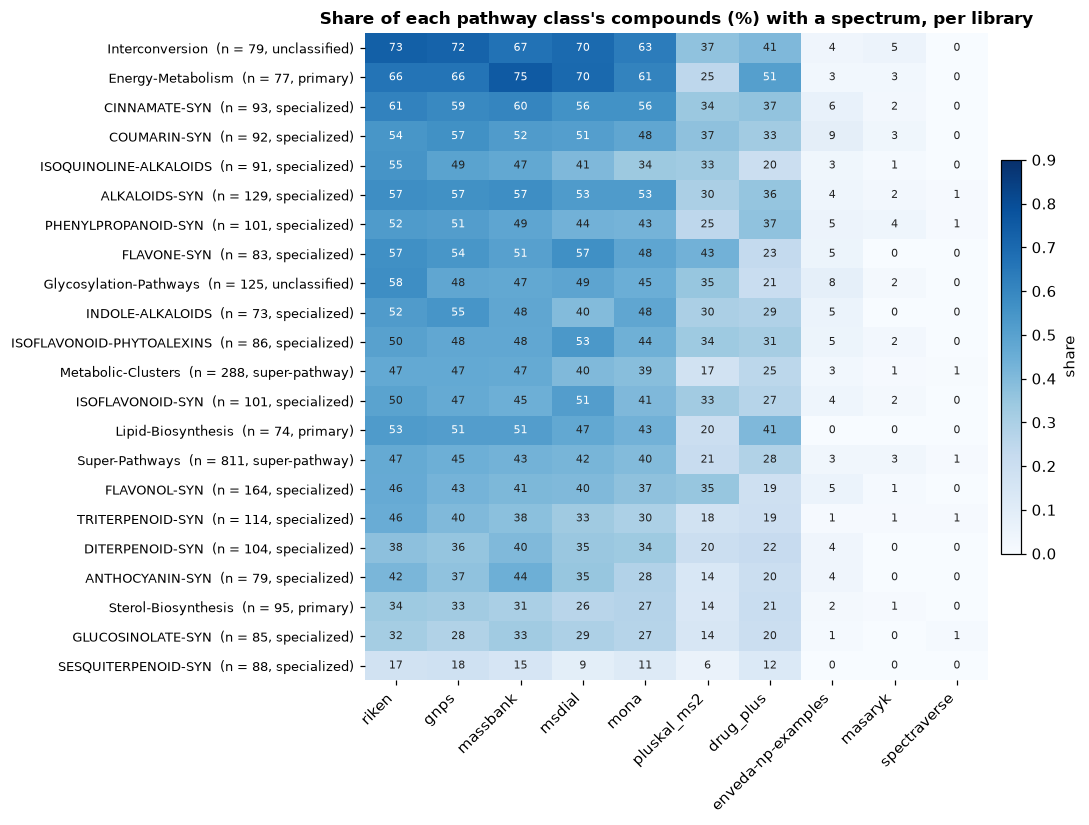

In [7]:
cm = mp.merge(cls[["plantcyc_id", "class"]].drop_duplicates(), on="plantcyc_id")
size = cm.groupby("class").k14.nunique().sort_values(ascending=False)
top = [c for c in size.index if size[c] >= 30][:22]
ck = {c: set(cm.k14[cm["class"] == c]) for c in top}
order_c = sorted(top, key=lambda c: -len(ck[c] & allc) / len(ck[c]))
Z = np.array([[len(ck[c] & S[l]) / len(ck[c]) for l in use] for c in order_c])
fig, ax = plt.subplots(figsize=(10, 7.6))
im = ax.imshow(Z, cmap="Blues", vmin=0, vmax=0.9, aspect="auto")
ax.set_xticks(range(len(use))); ax.set_xticklabels(use, rotation=45, ha="right")
cat_of = cat.set_index("class").category.to_dict()
ax.set_yticks(range(len(order_c))); ax.set_yticklabels([f"{c}  (n = {len(ck[c])}, {cat_of.get(c, '?').split(' ')[0]})" for c in order_c], fontsize=8.5)
for i in range(len(order_c)):
    for j in range(len(use)):
        ax.text(j, i, f"{100 * Z[i, j]:.0f}", ha="center", va="center", fontsize=7.5, color="white" if Z[i, j] > 0.5 else "#222")
ax.set_title("Share of each pathway class's compounds (%) with a spectrum, per library")
for s in ax.spines.values(): s.set_visible(False)
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, label="share")
fig.tight_layout(); fig.savefig(FIG / "class_by_library.png"); plt.show()

## What this shows

- Connectivity is concentrated in a few natural-product and metabolite libraries (RIKEN, GNPS, MassBank, MS-DIAL, MoNA); `enveda-180` has none.
- The libraries are nested, so adding a library after the first few adds little; the unique contributions are small.
- Coverage by spectra is about half of the compounds in every pathway category; specialized pathways are only slightly behind at pathway level. The class heatmap shows the gaps: sesquiterpenoid synthesis is lowest (at most 18 % of its compounds in any library), followed by glucosinolate and sterol biosynthesis (up to about a third); these are the classes where reference spectra cannot support an annotation. The best covered are interconversion, energy metabolism and cinnamate synthesis (about 60 to 75 % in the large libraries).

Limits: the match is on skeleton (`inchikey14`), so a stereoisomer or charge form of the right skeleton counts; a library match says a reference spectrum exists, not that it is good (precursor error and adduct are not filtered here); the category of a pathway is derived from its PlantCyc classes with the priority rule above.